# Practical 10 – PCA 3D Visualization and Explained Variance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
raw = load_wine(as_frame=True)


In [2]:
X = raw.data
y = raw.target
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=3)
coords = pca.fit_transform(scaled)
variance = pca.explained_variance_ratio_
print('Reduced:', coords.shape, 'Variance:', variance, 'Cumulative:', np.cumsum(variance))


Reduced: (178, 3) Variance: [0.36198848 0.1920749  0.11123631] Cumulative: [0.36198848 0.55406338 0.66529969]


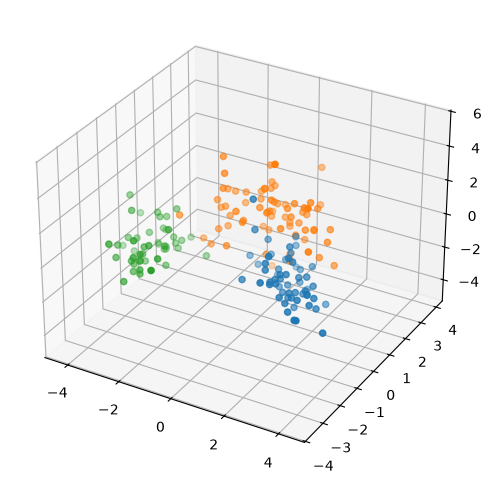

In [3]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
for c in sorted(y.unique()):
    mask = (y == c).to_numpy()
    ax.scatter(coords[mask, 0], coords[mask, 1], coords[mask, 2], label=raw.target_names[c])


Text(0, 0.5, 'Explained Variance %')

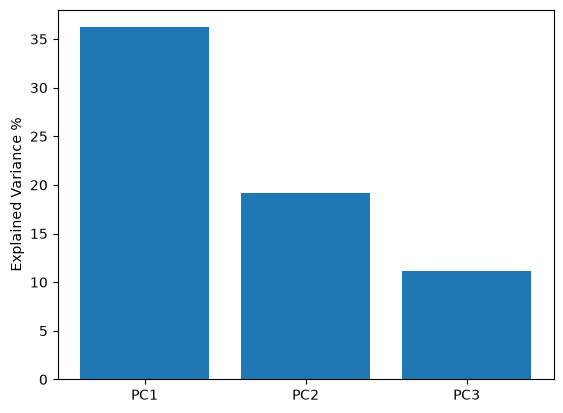

In [4]:
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.legend()
plt.show()
plt.bar(['PC1', 'PC2', 'PC3'], variance * 100)
plt.ylabel('Explained Variance %')


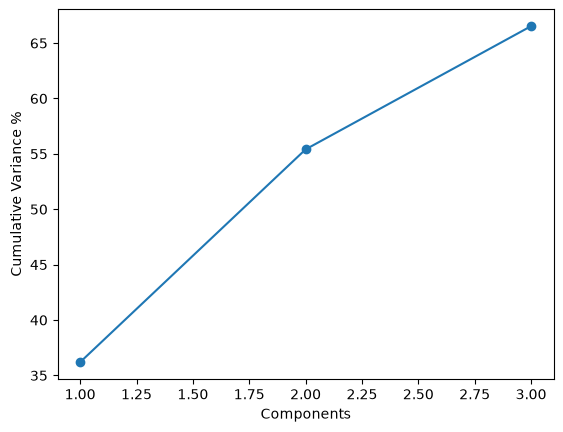

Components for 95% variance: 10


In [5]:
plt.show()
plt.plot([1, 2, 3], np.cumsum(variance) * 100, marker='o')
plt.xlabel('Components')
plt.ylabel('Cumulative Variance %')
plt.show()
full = PCA().fit(scaled)
print('Components for 95% variance:', np.searchsorted(np.cumsum(full.explained_variance_ratio_), 0.95) + 1)
